# Matplotlib Tasks

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

tips = sns.load_dataset("tips")
flights = sns.load_dataset("flights")
mpg = sns.load_dataset("mpg")

## Task 1: Line Plot

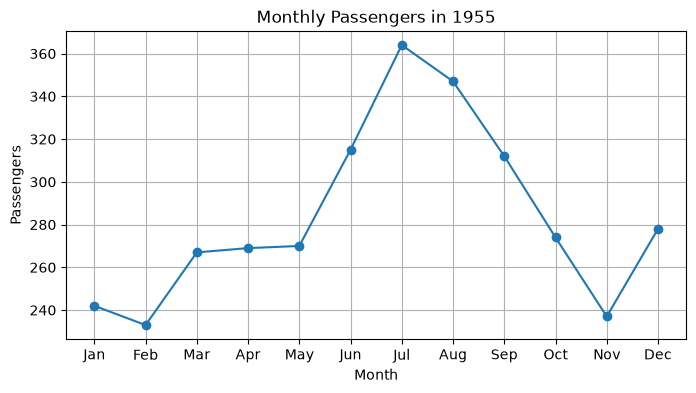

In [2]:
year = flights[flights["year"] == 1955]

plt.figure(figsize=(8, 4))
plt.plot(year["month"].astype(str), year["passengers"], marker="o")
plt.title("Monthly Passengers in 1955")
plt.xlabel("Month")
plt.ylabel("Passengers")
plt.grid(True)
plt.show()

## Task 2: Bar Chart

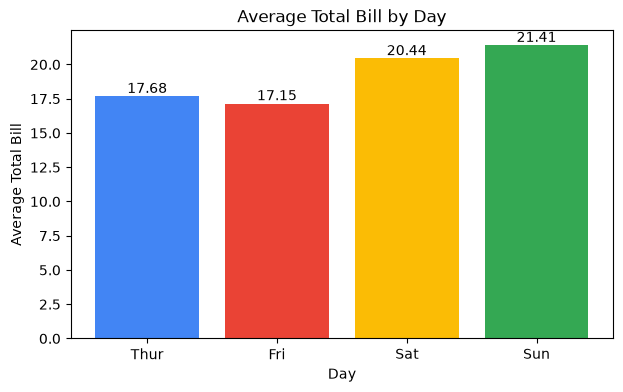

In [3]:
avg_bill = tips.groupby("day", observed=True)["total_bill"].mean()

plt.figure(figsize=(7, 4))
bars = plt.bar(avg_bill.index.astype(str), avg_bill.values, color=["#4285F4", "#EA4335", "#FBBC05", "#34A853"])
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{bar.get_height():.2f}", ha="center", va="bottom")
plt.title("Average Total Bill by Day")
plt.xlabel("Day")
plt.ylabel("Average Total Bill")
plt.show()

## Task 3: Horizontal Bar Chart

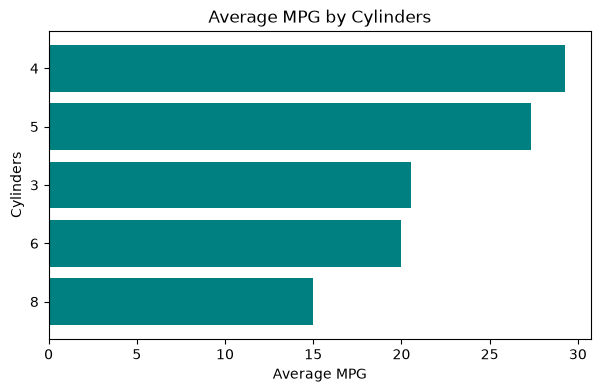

In [4]:
avg_mpg = mpg.groupby("cylinders")["mpg"].mean().sort_values()

plt.figure(figsize=(7, 4))
plt.barh(avg_mpg.index.astype(str), avg_mpg.values, color="teal")
plt.title("Average MPG by Cylinders")
plt.xlabel("Average MPG")
plt.ylabel("Cylinders")
plt.show()

## Task 4: Histogram

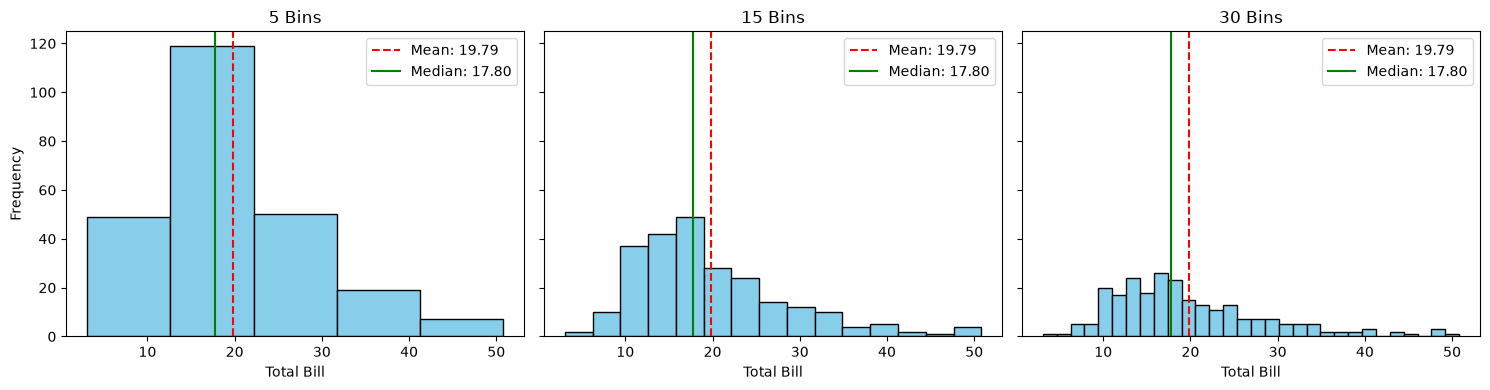

In [5]:
mean = tips["total_bill"].mean()
median = tips["total_bill"].median()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, bins in zip(axes, [5, 15, 30]):
    ax.hist(tips["total_bill"], bins=bins, color="skyblue", edgecolor="black")
    ax.axvline(mean, color="red", linestyle="--", label=f"Mean: {mean:.2f}")
    ax.axvline(median, color="green", linestyle="-", label=f"Median: {median:.2f}")
    ax.set_title(f"{bins} Bins")
    ax.set_xlabel("Total Bill")
    ax.legend()
axes[0].set_ylabel("Frequency")
plt.tight_layout()
plt.show()

## Task 5: Scatter Plot

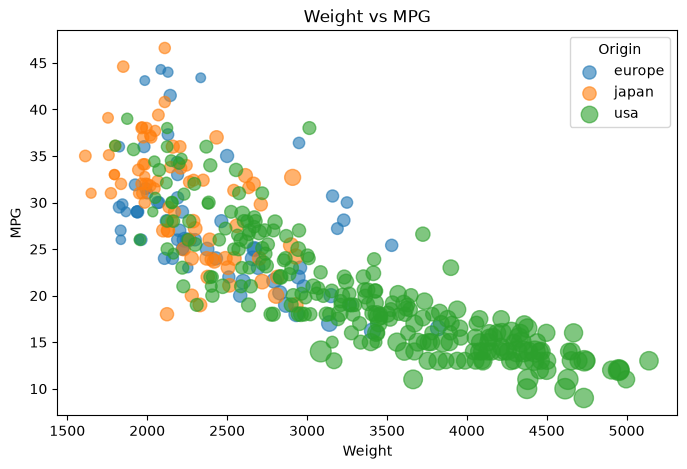

In [6]:
cars = mpg.dropna(subset=["horsepower", "mpg", "weight"])

plt.figure(figsize=(8, 5))
for origin, group in cars.groupby("origin"):
    plt.scatter(group["weight"], group["mpg"], s=group["horsepower"], alpha=0.6, label=origin)
plt.title("Weight vs MPG")
plt.xlabel("Weight")
plt.ylabel("MPG")
plt.legend(title="Origin")
plt.show()

## Task 6: Donut Chart

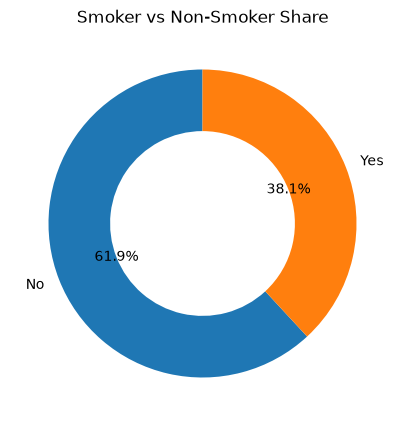

In [7]:
share = tips["smoker"].value_counts()

plt.figure(figsize=(5, 5))
plt.pie(share.values, labels=share.index.astype(str), autopct="%1.1f%%", startangle=90, wedgeprops={"width": 0.4})
plt.title("Smoker vs Non-Smoker Share")
plt.show()

## Task 7: Mini Dashboard

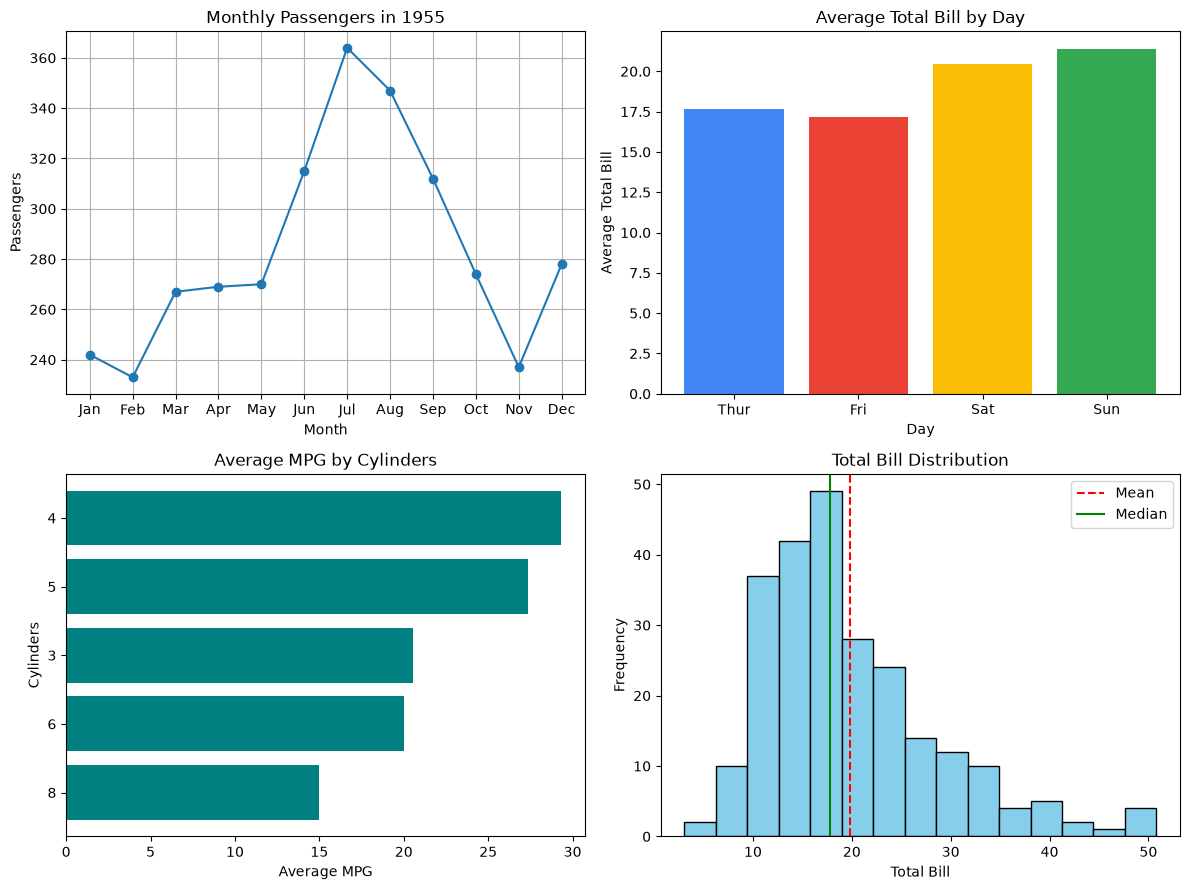

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].plot(year["month"].astype(str), year["passengers"], marker="o")
axes[0, 0].set_title("Monthly Passengers in 1955")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Passengers")
axes[0, 0].grid(True)

axes[0, 1].bar(avg_bill.index.astype(str), avg_bill.values, color=["#4285F4", "#EA4335", "#FBBC05", "#34A853"])
axes[0, 1].set_title("Average Total Bill by Day")
axes[0, 1].set_xlabel("Day")
axes[0, 1].set_ylabel("Average Total Bill")

axes[1, 0].barh(avg_mpg.index.astype(str), avg_mpg.values, color="teal")
axes[1, 0].set_title("Average MPG by Cylinders")
axes[1, 0].set_xlabel("Average MPG")
axes[1, 0].set_ylabel("Cylinders")

axes[1, 1].hist(tips["total_bill"], bins=15, color="skyblue", edgecolor="black")
axes[1, 1].axvline(mean, color="red", linestyle="--", label="Mean")
axes[1, 1].axvline(median, color="green", linestyle="-", label="Median")
axes[1, 1].set_title("Total Bill Distribution")
axes[1, 1].set_xlabel("Total Bill")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].legend()

plt.tight_layout()
plt.savefig("dashboard.png", dpi=300)
plt.show()